# Assignment 1.1 – Image Processing and Neural Networks

**Course:** Applied Computer Vision / Neural Networks

This notebook covers Fashion-MNIST neural-network classification, TensorFlow flower-image preprocessing, and OpenCV image resizing and color correction.

**Execution note:** Run the notebook from top to bottom. The flower dataset path is reused from the download cell so that the later cells do not depend on a separately hard-coded directory.

In [18]:
# PART 1 — LOAD FASHION-MNIST
# Import TensorFlow/Keras and load the built-in Fashion-MNIST training and test sets.
# Each image is a 28 x 28 grayscale image; each label is an integer from 0 to 9.

import tensorflow as tf
from tensorflow.keras.datasets import fashion_mnist
from tensorflow import keras

(X_train_full, y_train_full), (X_test, y_test) = keras.datasets.fashion_mnist.load_data()
print(X_train_full.shape)
print(X_test.shape)
print(y_train_full.shape)
print(y_test.shape)

(60000, 28, 28)
(10000, 28, 28)
(60000,)
(10000,)


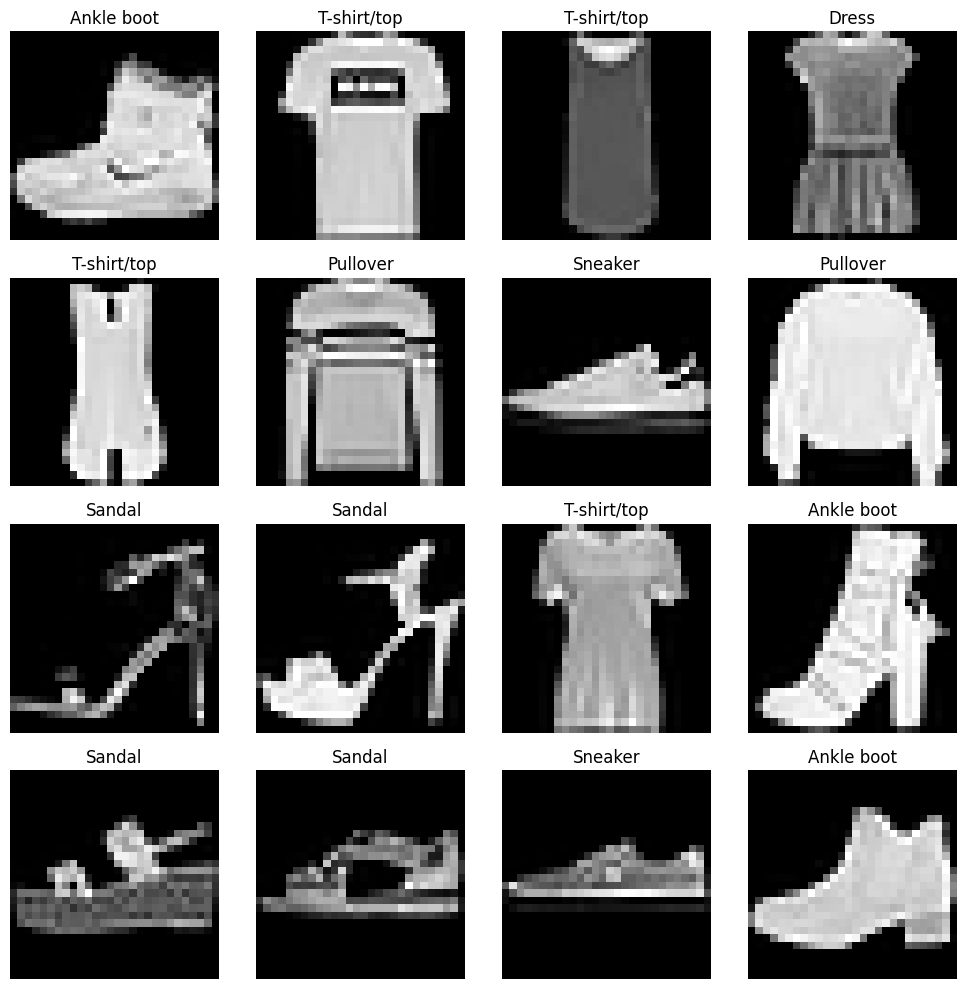

In [19]:
# PART 1 — VISUALIZE THE FIRST 16 TRAINING IMAGES
# Map each numeric class label to its human-readable clothing category.
# A 4 x 4 grid is used so that all 16 requested examples are visible together.

import matplotlib.pyplot as plt

fashion_category = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]

# Display the first 16 training images in a 4 x 4 grid.
fig, axs = plt.subplots(4, 4, figsize=(10, 10))
axs = axs.flatten()

for i in range(16):
    image = X_train_full[i]
    label = y_train_full[i]
    axs[i].imshow(image, cmap="gray")
    axs[i].set_title(fashion_category[label])
    axs[i].axis("off")

plt.tight_layout()
plt.show()


In [20]:
# PART 1 — CHECK THE CLASS DISTRIBUTION
# Count how many training examples belong to each of the 10 Fashion-MNIST classes.
# This is a quick check of how examples are distributed across the labels.

import numpy as np

NUM_CLASSES = len(fashion_category)

class_counts = np.bincount(y_train_full, minlength=NUM_CLASSES)
# print(class_counts)

for i, count in enumerate(class_counts):
    print(f"{fashion_category[i]}      ===> {count} images")


T-shirt/top      ===> 6000 images
Trouser      ===> 6000 images
Pullover      ===> 6000 images
Dress      ===> 6000 images
Coat      ===> 6000 images
Sandal      ===> 6000 images
Shirt      ===> 6000 images
Sneaker      ===> 6000 images
Bag      ===> 6000 images
Ankle boot      ===> 6000 images


In [21]:
# PART 1 — CREATE VALIDATION DATA AND NORMALIZE PIXELS
# Keep 48,000 images for training and use the remaining 12,000 (20%) for validation.
# Divide pixel values by 255 so that input values are scaled from [0, 255] to [0, 1].
# Apply the same normalization to the independent test set.

# Split out a validation set using NumPy slicing
# Split the the train data into 80% for training and 20% for validation
X_train, X_valid = X_train_full[:48000], X_train_full[48000:]
y_train, y_valid = y_train_full[:48000], y_train_full[48000:]
print(X_train.shape)
print(X_valid.shape)
print(y_train.shape)
print(y_valid.shape)

# Normalize the image data (scale pixel integers down to 0.0 - 1.0 floats)
X_train = X_train / 255.0
X_valid = X_valid / 255.0
X_test = X_test / 255.0


(48000, 28, 28)
(12000, 28, 28)
(48000,)
(12000,)


In [22]:
# PART 1 — BUILD AND TRAIN THE NEURAL NETWORK
# The Flatten layer converts each 28 x 28 image into 784 input features.
# The single hidden Dense layer has 128 neurons and uses ReLU activation.
# The 10-neuron Softmax output returns a probability for each clothing category.
# Sparse categorical cross-entropy is appropriate because labels are integer class IDs.
# Train for 20 epochs using batches of 128 and monitor the held-out validation set.

# Part 1: Fashion-MNIST neural network
OUTPUT_DIR = "aai_521_module_1_outputs"

BATCH_SIZE = 128
EPOCHS = 20

model = tf.keras.models.Sequential(
    [
        tf.keras.layers.Input(shape=(28, 28)),
        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(128, activation="relu"),  # One hidden layer: 128 nodes
        tf.keras.layers.Dense(NUM_CLASSES, activation="softmax")
    ],
    name="Fashion_MNIST_NN"
)

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history = model.fit(
    X_train,
    y_train,
    batch_size=BATCH_SIZE,
    epochs=EPOCHS,
    validation_data=(X_valid, y_valid)
)


Epoch 1/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7970 - loss: 0.5896 - val_accuracy: 0.8421 - val_loss: 0.4485
Epoch 2/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8545 - loss: 0.4199 - val_accuracy: 0.8542 - val_loss: 0.4134
Epoch 3/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8679 - loss: 0.3780 - val_accuracy: 0.8618 - val_loss: 0.3969
Epoch 4/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8741 - loss: 0.3537 - val_accuracy: 0.8727 - val_loss: 0.3561
Epoch 5/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8831 - loss: 0.3288 - val_accuracy: 0.8697 - val_loss: 0.3640
Epoch 6/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8868 - loss: 0.3147 - val_accuracy: 0.8741 - val_loss: 0.3526
Epoch 7/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8921 - loss: 0.2994 - val_accuracy: 0.8763 - val_loss: 0.3415
Epoch 8/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8956 - loss: 0.2866 - val_accuracy: 0.

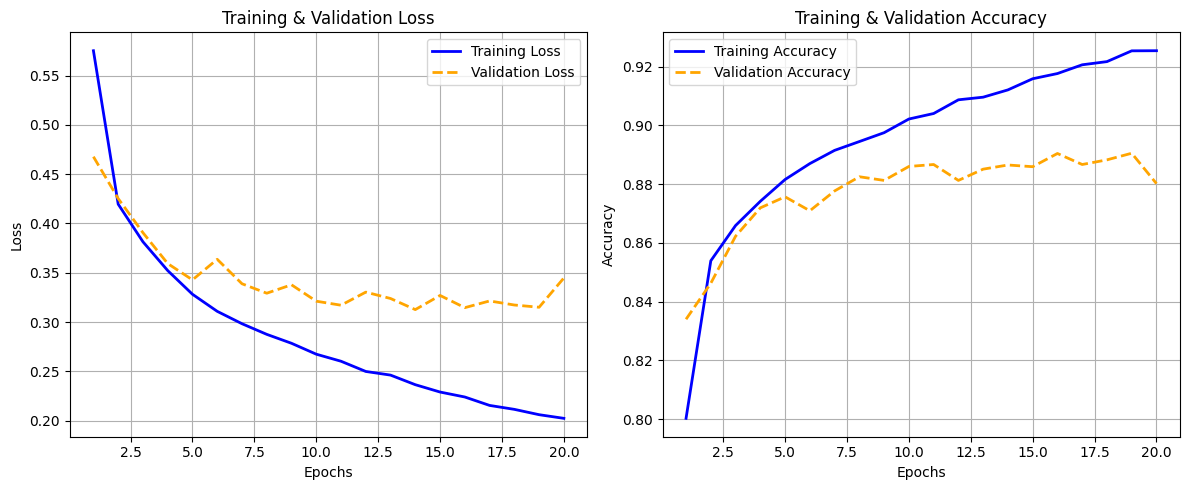

In [6]:
# PART 1 — PLOT THE LEARNING CURVES
# Read accuracy and loss values recorded by model.fit() for every epoch.
# Compare training and validation curves to assess learning and possible overfitting.
# A widening gap (training improves while validation stalls/worsens) can indicate overfitting.

import matplotlib.pyplot as plt

# Extract metrics from the history object
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']
epochs_range = range(1, len(acc) + 1)

# Create a figure frame with two subplots side-by-side
plt.figure(figsize=(12, 5))

# Plot 1: Loss Curves
plt.subplot(1, 2, 1)
plt.plot(epochs_range, loss, label='Training Loss', color='blue', lw=2)
plt.plot(epochs_range, val_loss, label='Validation Loss', color='orange', lw=2, linestyle='--')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Training & Validation Loss')
plt.legend()
plt.grid(True)

# Plot 2: Accuracy Curves
plt.subplot(1, 2, 2)
plt.plot(epochs_range, acc, label='Training Accuracy', color='blue', lw=2)
plt.plot(epochs_range, val_acc, label='Validation Accuracy', color='orange', lw=2, linestyle='--')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.title('Training & Validation Accuracy')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()


## Learning-curve observations and suggestions

Based on the recorded Fashion-MNIST training output:

- Training accuracy increases to approximately **92.55%**, while validation accuracy finishes at approximately **88.94%**.
- Training loss decreases throughout training and finishes at approximately **0.204**.
- Validation loss reaches a lower value earlier (around epoch 15) and then fluctuates/increases slightly, finishing at approximately **0.327**.
- The gap between training and validation performance, particularly in the later epochs, indicates **some overfitting**. The validation accuracy also improves more slowly and largely plateaus in the later epochs.

### Suggestions to improve generalization

1. **Dropout:** Add `tf.keras.layers.Dropout(0.2)` after the 128-node hidden layer. This reduces reliance on individual neurons during training.
2. **Early stopping:** Use `tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)` to stop when validation loss no longer improves and restore the best weights.
3. **L2 regularization:** Add a small L2 penalty to the Dense layer to discourage overly large weights.

The best next experiment would be to add Dropout and EarlyStopping, retrain the model, and compare the validation curves with the original model.


## Part 2 – TensorFlow flower images

The following cells download the TensorFlow flower dataset, count the images, inspect one image from each category, resize the data, and apply Keras preprocessing.

In [7]:
# PART 2 — DOWNLOAD AND EXTRACT THE FLOWER PHOTOS DATASET
# Keras downloads the TensorFlow flower_photos archive and extracts it locally.
# pathlib.Path makes it easier to inspect folders and image files independent of OS.
# The recursive glob finds JPG files in all five category folders.

import pathlib
import tensorflow as tf

# 1. Define the official dataset archive download link
dataset_url = "http://download.tensorflow.org/example_images/flower_photos.tgz"

# 2. Let Keras download and extract (.tgz) the archive natively onto your local disk.
# This method manages folder paths safely and returns the exact location path string.
data_dir_path = tf.keras.utils.get_file(
    fname='flower_photos',
    origin=dataset_url,
    untar=True,
    cache_dir='.'  # Forces it to use the local directory instead of the hidden system path
)

# 3. Convert the downloaded path string into a Path object instance
data_dir = pathlib.Path(data_dir_path)

# 4. Search recursively for all JPG image file paths across the 5 subfolders
all_images = list(data_dir.glob('**/*.jpg'))

# 5. Output the calculations to your PyCharm console window
print(f"Dataset successfully downloaded to: {data_dir_path}")
print(f"Total number of images in the dataset: {len(all_images)}")


Dataset successfully downloaded to: ./datasets/flower_photos
Total number of images in the dataset: 7340


In [8]:
# PART 2(a) — COUNT IMAGES IN EACH FLOWER CATEGORY
# Reuse data_dir from the download cell so every later step points to the same dataset.
# Inspect each category folder, count supported image extensions, and calculate the total.

# Part 2(a): Count images in each of the five flower subfolders.
# Reuse data_dir created in the dataset download cell above.
total_number_of_images = 0

print("Image count by flower category:\n")

for folder in sorted(data_dir.iterdir()):
    if folder.is_dir():
        image_files = [
            path for path in folder.iterdir()
            if path.is_file() and path.suffix.lower() in {".jpg", ".jpeg", ".png"}
        ]
        count = len(image_files)
        total_number_of_images += count
        print(f"{folder.name}: {count} images")

print(f"\nTotal number of images: {total_number_of_images}")
print(f"Number of category folders: {sum(1 for p in data_dir.iterdir() if p.is_dir())}")


Image count by flower category:

daisy: 633 images
dandelion: 898 images
flower_photos: 0 images
roses: 641 images
sunflowers: 699 images
tulips: 799 images

Total number of images: 3670
Number of category folders: 6


Category: daisy | File: 100080576_f52e8ee070_n.jpg | Original size: (320, 263)


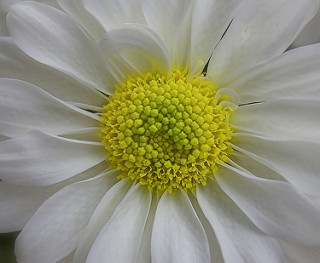

Category: dandelion | File: 10043234166_e6dd915111_n.jpg | Original size: (320, 213)


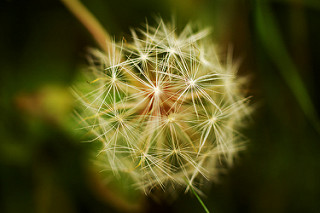

Category: roses | File: 10090824183_d02c613f10_m.jpg | Original size: (179, 240)


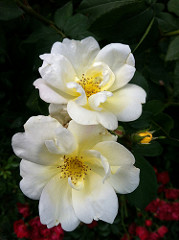

Category: sunflowers | File: 1008566138_6927679c8a.jpg | Original size: (500, 330)


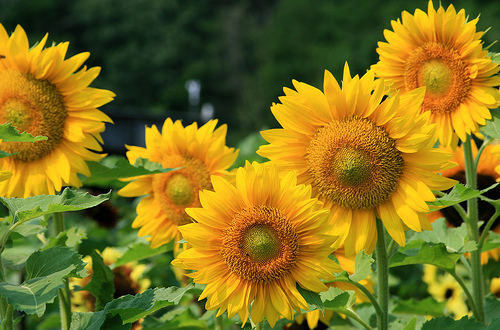

Category: tulips | File: 100930342_92e8746431_n.jpg | Original size: (320, 209)


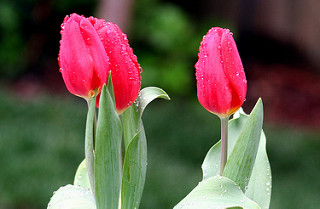

In [23]:
# PART 2(b) — DISPLAY ONE IMAGE PER CATEGORY USING PILLOW
# Pillow opens image files and preserves their original image dimensions.
# Display one example from each category folder to visually inspect the dataset.

# Part 2(b): Display at least one flower from each category using Pillow (PIL).
from PIL import Image
from IPython.display import display

for folder in sorted(data_dir.iterdir()):
    if folder.is_dir():
        image_files = sorted(
            path for path in folder.iterdir()
            if path.suffix.lower() in {".jpg", ".jpeg", ".png"}
        )
        if image_files:
            image_path = image_files[0]
            with Image.open(image_path) as image:
                print(f"Category: {folder.name} | File: {image_path.name} | Original size: {image.size}")
                display(image.copy())


Found 3670 files belonging to 5 classes.
Using 2936 files for training.
Found 3670 files belonging to 5 classes.
Using 734 files for validation.
Class names: ['daisy', 'dandelion', 'roses', 'sunflowers', 'tulips']
Number of classes: 5


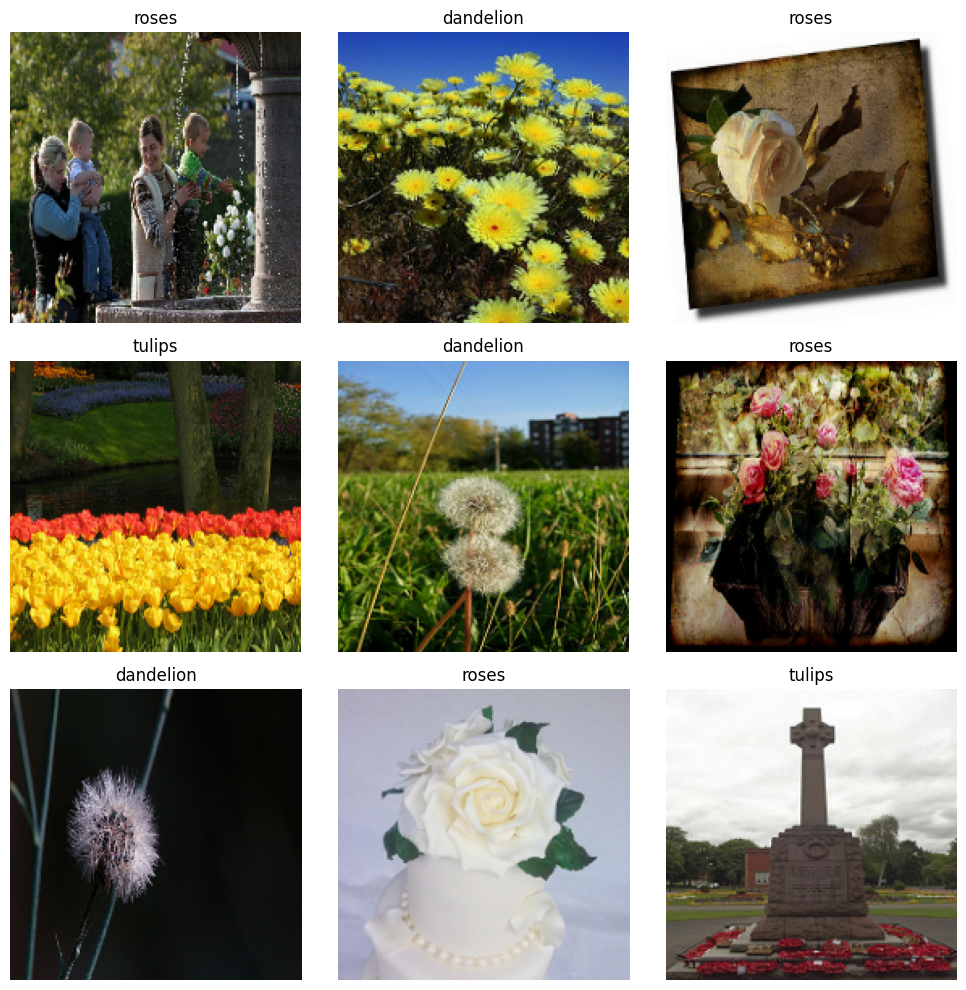

In [27]:
# PART 2(c) AND 2(d) — LOAD, RESIZE, AND SAMPLE FLOWER IMAGES
# image_dataset_from_directory infers class labels from the names of the subfolders.
# The same 20% split percentage and random seed ensure consistent train/validation splits.
# image_size resizes every image to 180 x 180; batching groups images for efficient processing.
# Print the class names/count, then randomly choose nine examples from one training batch.

# Part 2(c): Load the flower dataset and resize images to 180 x 180.
import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np

data_dir_path = "datasets/flower_photos"
IMAGE_SIZE = (180, 180)
TRAIN_BATCH_SIZE = 32
VALIDATION_BATCH_SIZE = 32
SEED = 123

train_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir_path,
    validation_split=0.2,
    subset="training",
    seed=SEED,
    image_size=IMAGE_SIZE,
    batch_size=TRAIN_BATCH_SIZE
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir_path,
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    image_size=IMAGE_SIZE,
    batch_size=VALIDATION_BATCH_SIZE
)

class_names = train_ds.class_names
num_classes = len(class_names)

print("Class names:", class_names)
print("Number of classes:", num_classes)

# Part 2(d): Randomly display 9 images from the training dataset.
images_batch, labels_batch = next(iter(train_ds))

rng = np.random.default_rng(SEED)
random_indices = rng.choice(len(images_batch), size=9, replace=False)

plt.figure(figsize=(10, 10))
for plot_position, image_index in enumerate(random_indices, start=1):
    plt.subplot(3, 3, plot_position)
    plt.imshow(images_batch[image_index].numpy().astype("uint8"))
    label_index = int(labels_batch[image_index].numpy())
    plt.title(class_names[label_index])
    plt.axis("off")

plt.tight_layout()
plt.show()


### Part 2(d): Observations – barriers to accurate flower classification

When reviewing the sample flower images, the following factors can make classification difficult:

- **Similar appearance:** Different flower categories may have similar petal shapes, colors, or overall structures.
- **Variation within a category:** Flowers from the same category can look different because of species, maturity, lighting, and camera angle.
- **Background clutter:** Leaves, grass, soil, other flowers, and objects may distract the model from the flower itself.
- **Scale and orientation:** Flowers may appear at different distances, sizes, rotations, and positions in the image.
- **Lighting and image quality:** Shadows, overexposure, blur, and low resolution can hide important visual features.
- **Occlusion and multiple flowers:** A flower may be partly hidden, or multiple flowers may appear in one image.

These challenges mean that the model should learn robust flower features rather than relying only on background, color, or image position. Resizing and data augmentation can help improve generalization, although augmentation cannot fully solve ambiguous or poorly captured images.


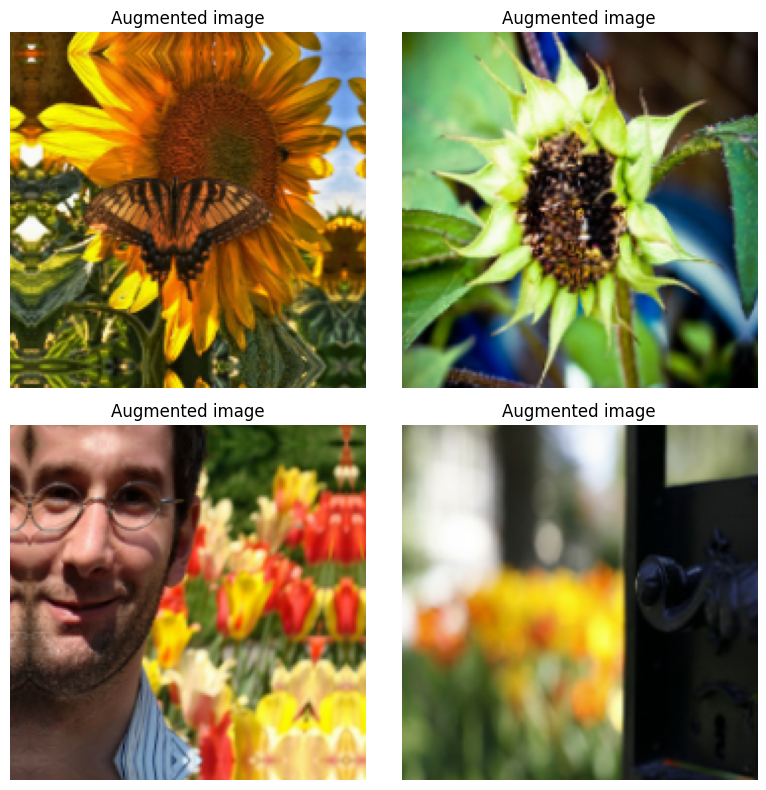

Epoch 1/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 28s 298ms/step - accuracy: 0.3512 - loss: 1.4872 - val_accuracy: 0.4155 - val_loss: 1.3403
Epoch 2/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 26s 282ms/step - accuracy: 0.4513 - loss: 1.2594 - val_accuracy: 0.4659 - val_loss: 1.2261
Epoch 3/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 24s 261ms/step - accuracy: 0.4772 - loss: 1.2003 - val_accuracy: 0.4946 - val_loss: 1.1938
Epoch 4/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 26s 281ms/step - accuracy: 0.5116 - loss: 1.1651 - val_accuracy: 0.5409 - val_loss: 1.1593
Epoch 5/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 28s 308ms/step - accuracy: 0.5368 - loss: 1.1314 - val_accuracy: 0.5531 - val_loss: 1.1180
Epoch 6/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 27s 294ms/step - accuracy: 0.5572 - loss: 1.1044 - val_accuracy: 0.5286 - val_loss: 1.1255
Epoch 7/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 28s 308ms/step - accuracy: 0.5623 - loss: 1.0845 - val_accuracy: 0.5518 - val_loss: 1.1056
Epoch 8/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 27s 295ms/step - accuracy: 0.5773 - loss: 1.0636 - val_accu

In [30]:
# PART 2(e) — PREPROCESS AND AUGMENT FLOWER IMAGES
# Rescaling converts pixel values to [0, 1]. The random layers augment images during training.
# Shear, zoom, and horizontal flip introduce realistic variations to improve generalization.
# First visualize a few augmented examples, then use the same preprocessing in the classifier.
# GlobalAveragePooling2D reduces the feature map to a compact vector before the Dense layers.
# The Softmax output has one probability per flower category.

# Part 2(e): Keras preprocessing and image augmentation.
# The augmentation layers are active during training and are applied to training images.
import tensorflow as tf
from tensorflow.keras import layers

data_augmentation = tf.keras.Sequential(
    [
        layers.Rescaling(1.0 / 255.0),                 # Rescale pixels from [0, 255] to [0, 1]
        layers.RandomShear(x_factor=0.2, y_factor=0.0), # 20% horizontal shear
        layers.RandomZoom(height_factor=(-0.2, 0.2)),   # Up to 20% zoom in/out
        layers.RandomFlip(mode="horizontal")            # Random horizontal flip
    ],
    name="flower_preprocessing"
)

# Display examples after applying the preprocessing/augmentation pipeline.
sample_images, _ = next(iter(train_ds))
augmented_images = data_augmentation(sample_images[:4], training=True)

plt.figure(figsize=(8, 8))
for i in range(4):
    plt.subplot(2, 2, i + 1)
    plt.imshow(tf.clip_by_value(augmented_images[i], 0.0, 1.0).numpy())
    plt.title("Augmented image")
    plt.axis("off")
plt.tight_layout()
plt.show()

# Additional practice: train a flower classifier using the preprocessing pipeline.
# GlobalAveragePooling2D keeps the model much smaller than Flatten() after Conv2D.
flower_model = tf.keras.Sequential(
    [
        layers.Input(shape=(180, 180, 3)),
        data_augmentation,
        layers.Conv2D(32, (3, 3), activation="relu"),
        layers.MaxPooling2D((2, 2)),
        layers.Conv2D(64, (3, 3), activation="relu"),
        layers.MaxPooling2D((2, 2)),
        layers.GlobalAveragePooling2D(),
        layers.Dense(128, activation="relu"),
        layers.Dense(num_classes, activation="softmax")
    ],
    name="Flower_Classification_Model"
)

flower_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

flower_history = flower_model.fit(
    train_ds,
    epochs=EPOCHS,
    validation_data=val_ds
)


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 187ms/step


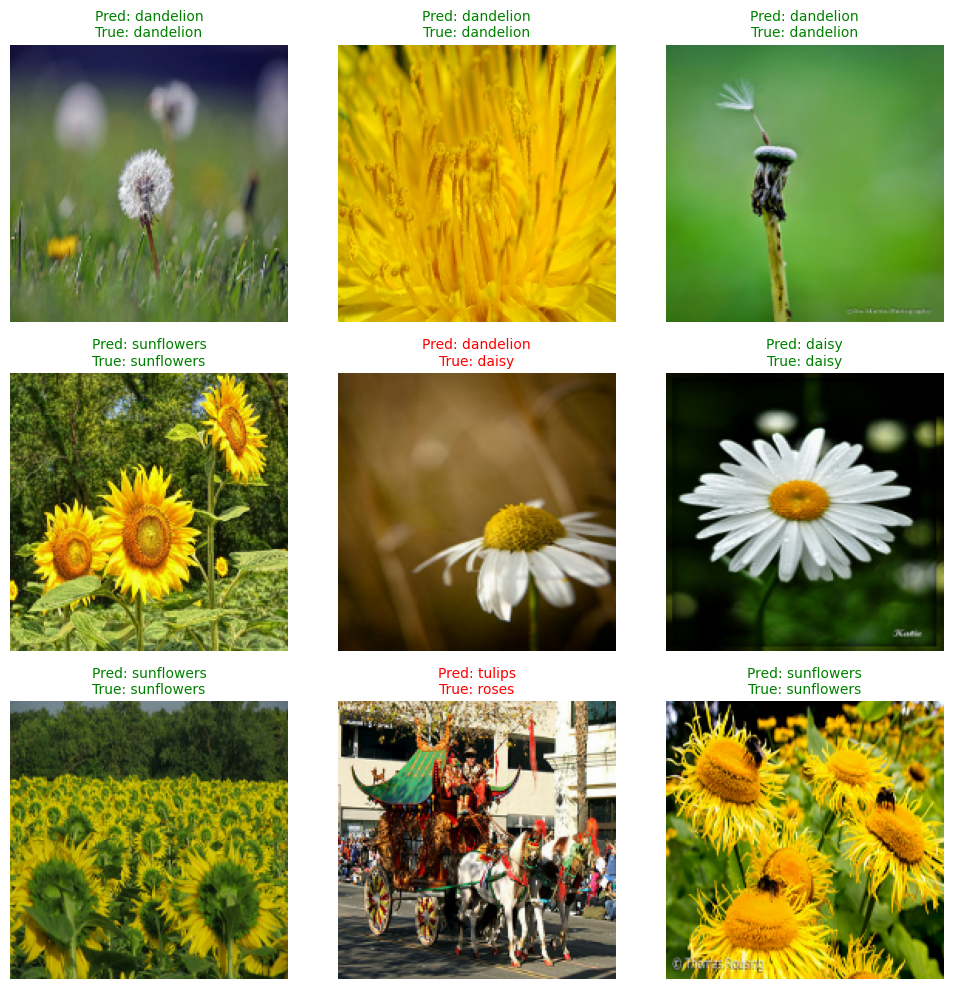

In [31]:
# OPTIONAL MODEL CHECK — PREDICT A BATCH OF VALIDATION IMAGES
# Predict a batch that was not used to update the model weights.
# For each of the first nine images, compare the predicted category with the true label.
# Green titles indicate a correct prediction; red titles indicate a mismatch.

# Predict a Batch of Validation Images
import matplotlib.pyplot as plt
import numpy as np

# 1. Grab exactly one batch of 32 images from your validation pipeline
images_batch, labels_batch = next(iter(val_ds))

# 2. Generate predictions for the entire batch all at once
predictions = flower_model.predict(images_batch)
class_names = train_ds.class_names

# 3. Setup a 3x3 grid window to visualize 9 images from this batch
plt.figure(figsize=(10, 10))
for i in range(9):
    plt.subplot(3, 3, i + 1)

    # Render the image array
    plt.imshow(images_batch[i].numpy().astype("uint8"))

    # Find the model's top predicted label index and compare it to the true label
    predicted_label = class_names[np.argmax(predictions[i])]
    true_label = class_names[labels_batch[i]]

    # Change the text color to green if the model is right, red if it's wrong!
    color = 'green' if predicted_label == true_label else 'red'

    plt.title(f"Pred: {predicted_label}\nTrue: {true_label}", color=color, fontsize=10)
    plt.axis("off")

plt.tight_layout()
plt.show()


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step
Testing File: 4550117239_5907aaba4c.jpg
True Category: 'tulips' | Predicted: 'tulips' (96.09%)


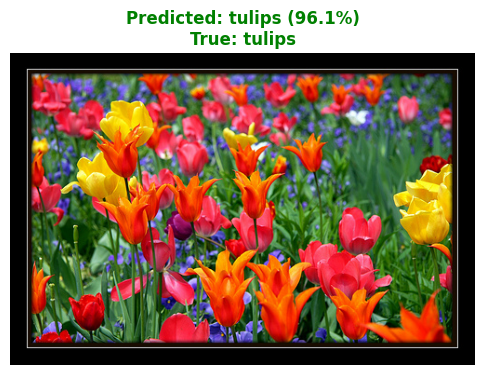

In [32]:
# OPTIONAL MODEL CHECK — PREDICT ONE LOCAL FLOWER IMAGE
# Select a random image from the same dataset directory used in the earlier cells.
# Resize a copy to the model's required 180 x 180 input size for prediction.
# Keep the original image dimensions for display, and report the predicted class/confidence.

# Test on a Single Image from the Local Flower Dataset

import random
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
import pathlib

# 1. Point to your local dataset directory inside your project folder
# Keep using data_dir from the dataset download cell; this avoids path mismatches.

# 2. Grab the local path list of all JPG image files available on your disk
all_local_images = list(data_dir.glob('**/*.jpg'))

if all_local_images:
    # 3. Pick one image file path completely at random from your folder structure
    random_image_path = random.choice(all_local_images)

    # 4. Process the image for the model (Resized to 180x180 so the network can read it)
    model_img = tf.keras.utils.load_img(
        random_image_path, target_size=(180, 180)
    )
    img_array = tf.keras.utils.img_to_array(model_img)
    img_array = tf.expand_dims(img_array, 0)

    # 5. Load the completely ORIGINAL image footprint for visual display
    # Leaving out target_size keeps the full original width, height, and resolution
    display_img = tf.keras.utils.load_img(random_image_path)

    # 6. Run the prediction pipeline
    predictions = flower_model.predict(img_array)
    score = predictions[0]

    # 7. Extract class names and labels
    class_names = train_ds.class_names
    predicted_class = class_names[int(np.argmax(score))]
    true_class = random_image_path.parent.name
    confidence = 100 * float(np.max(score))

    print(f"Testing File: {random_image_path.name}")
    print(f"True Category: '{true_class}' | Predicted: '{predicted_class}' ({confidence:.2f}%)")

    # 8. DISPLAY THE ORIGINAL VISUAL IMAGE
    plt.figure(figsize=(6, 6))

    # Render the raw, untouched original image object
    plt.imshow(display_img)

    # Color code the header: Green if correct, Red if incorrect
    title_color = 'green' if predicted_class == true_class else 'red'

    # Place text styling on top of the image display frame
    plt.title(
        f"Predicted: {predicted_class} ({confidence:.1f}%)\nTrue: {true_class}",
        color=title_color,
        fontsize=12,
        fontweight='bold'
    )

    plt.axis("off")  # Remove grid lines and axes numbers
    plt.show()       # Open the native graphic pop-up window

else:
    print("No images found in your local project directory folder structure.")


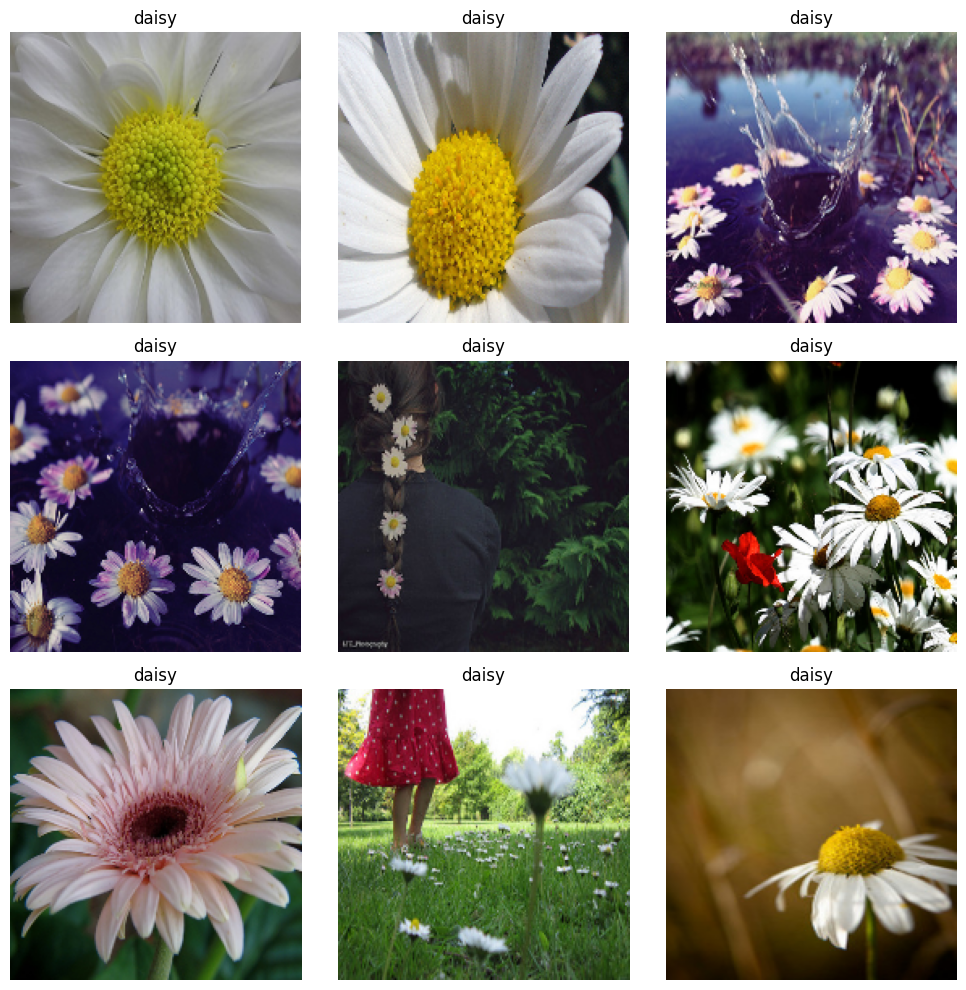

In [34]:
# PART 3 — USE OPENCV TO RESIZE AND CORRECT IMAGE COLORS
# OpenCV loads color images in BGR channel order by default, unlike Matplotlib's RGB order.
# Resize each selected image to 180 x 180, then convert BGR to RGB before displaying it.

# Part 3(a) and 3(b): OpenCV image loading, resizing, and color correction.
import pathlib
import cv2
import matplotlib.pyplot as plt

all_local_images = sorted(data_dir.glob("**/*.jpg"))

if not all_local_images:
    raise FileNotFoundError(f"No JPG images found under: {data_dir}")

plt.figure(figsize=(10, 10))

for i, image_path in enumerate(all_local_images[:9], start=1):
    # OpenCV reads color images in BGR order by default.
    img_bgr = cv2.imread(str(image_path))

    if img_bgr is None:
        print(f"Could not read image: {image_path}")
        continue

    # Resize to the required 180 x 180 dimensions.
    img_resized = cv2.resize(img_bgr, (180, 180))

    # Convert BGR to RGB so Matplotlib displays natural/normal colors.
    img_rgb = cv2.cvtColor(img_resized, cv2.COLOR_BGR2RGB)

    plt.subplot(3, 3, i)
    plt.imshow(img_rgb)
    plt.title(image_path.parent.name)
    plt.axis("off")

plt.tight_layout()
plt.show()
